# Equivariant PDE Discovery: Nonlinear Diffusion (Porous Medium Equation)

We study the **porous medium equation** (m=2) on the periodic domain $[0,L]^2$:
$$f_t = \nabla\cdot(f^2\nabla f) = f^2\Delta f + 2f|\nabla f|^2$$

The O(2)-equivariant library contains 20 operators $N_0,\ldots,N_{19}$.
The true equation activates $N_6 = f^2\Delta f$ (coefficient +1) and $N_8 = f|\nabla f|^2$ (coefficient +2).

In [1]:
# standard imports
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
plt.rcParams['figure.figsize'] = (14, 4)

# add parent directory with custom library to path
import sys
sys.path.insert(0, '..')

# simulation tools (ground truth data)
from simulations import porous_medium, make_regression_data

# library of PDE terms (respects the active derivative backend)
import derivatives
from library import build_equivariant_library, build_standard_library

# regression tools
from regression import TrainSTRidge

# utilities
from utils import print_pde, rotation_90


## 1. Simulate PME (m=2) via explicit Euler + spectral derivatives

$$f_t = f^2\Delta f + 2f|\nabla f|^2, \qquad f(0,\mathbf{x}) = \exp\!\left(-\frac{|\mathbf{x}-\mathbf{c}|^2}{2\sigma^2}\right)$$

In [2]:
# Simulation parameters
N          = 64          # grid points per direction
L          = 6 * np.pi  # domain side length
T_end      = 2.0        # end time
dt         = 0.002      # time step (explicit Euler)
save_every = 25         # save one snapshot every 25 steps

snapshots, times = porous_medium(
    N=N, L=L, T_end=T_end, dt=dt, save_every=save_every, seed=42,
)
print(f'{len(snapshots)} snapshots, t in [{times[0]:.2f}, {times[-1]:.2f}]')
print(f'f range: [{snapshots.min():.4f}, {snapshots.max():.4f}]')


41 snapshots, t in [0.00, 2.00]
f range: [0.0000, 0.9993]


/tmp/ipykernel_470436/3974111512.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


saved dynamics figure


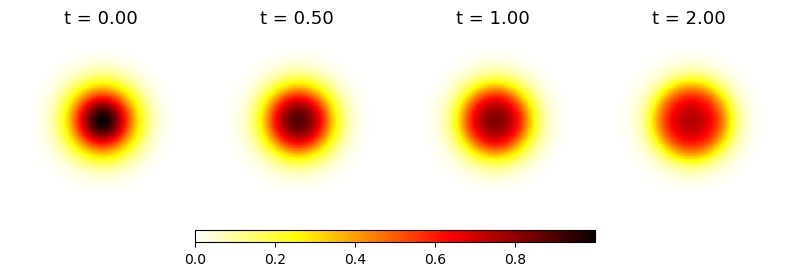

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(8, 3))

pidx = [0, len(snapshots)//4, len(snapshots)//2, -1]
vmax = snapshots[0].max()
for ax, idx in zip(axes, pidx):
    im = ax.imshow(snapshots[idx], cmap='hot_r', vmin=0, vmax=vmax,
                   origin='lower', extent=[0, L, 0, L])
    ax.set_title(f't = {times[idx]:.2f}', fontsize=13)
    ax.axis('off')

cbar_ax = fig.add_axes([0.25, 0.1, 0.5, 0.04])
fig.colorbar(im, cax=cbar_ax, orientation='horizontal')

plt.tight_layout()
plt.savefig('../results/figures/nonlinear_diffusion_snapshots.pdf', bbox_inches='tight')
plt.savefig('../../latex/figures/nonlinear_diffusion_snapshots.pdf', bbox_inches='tight')
print('saved dynamics figure')


## 2. Extract data for regression

We estimate $f_t$ by central finite difference. Because PME solutions have compact support we restrict sampling to points where $f > 0.05$.

In [4]:
n_per_snap = 200

f_snaps, ft_snaps, idx_sets, dt_snap = make_regression_data(
    snapshots, times, n_per_snap=n_per_snap, seed=0,
)

# for PME we additionally threshold on f > 0.05
threshold = 0.05
Ft_rows = []
idx_sets_pme = []
for s in range(len(f_snaps)):
    fs = f_snaps[s]
    mask = (fs > threshold).ravel()
    avail = np.where(mask)[0]
    ns = min(n_per_snap, len(avail))
    rng_s = np.random.default_rng(s)
    chosen = rng_s.choice(avail, ns, replace=False)
    idx_sets_pme.append(chosen)
    Ft_rows.append(ft_snaps[s].ravel()[chosen])

Ft_all = np.concatenate(Ft_rows)
print(f'{len(f_snaps)} interior snapshots, dt_snap = {dt_snap:.4f}')
print(f'Total regression points: {len(Ft_all)}')


39 interior snapshots, dt_snap = 0.0500
Total regression points: 7800


## 3. Libraries of differential terms

We compute the operator values over the full grid for each snapshot, then subsample.

In [5]:
Theta_eq_rows_spec, Theta_std_rows_spec = [], []
Theta_eq_rows_poly, Theta_std_rows_poly = [], []

for s in range(len(f_snaps)):
    fs  = f_snaps[s]
    idx = idx_sets_pme[s]
    with derivatives.use_backend('spectral'):
        Th_eq,  desc_eq  = build_equivariant_library(fs, L, L)
        Th_std, desc_std = build_standard_library(fs, L, L, max_order=4, max_poly=3)
    Theta_eq_rows_spec.append(Th_eq[idx])
    Theta_std_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq,  _ = build_equivariant_library(fs, L, L)
        Th_std, _ = build_standard_library(fs, L, L, max_order=4, max_poly=3)
    Theta_eq_rows_poly.append(Th_eq[idx])
    Theta_std_rows_poly.append(Th_std[idx])

Theta_eq_spec  = np.vstack(Theta_eq_rows_spec).astype(float)
Theta_std_spec = np.vstack(Theta_std_rows_spec).astype(float)
Theta_eq_poly  = np.vstack(Theta_eq_rows_poly).astype(float)
Theta_std_poly = np.vstack(Theta_std_rows_poly).astype(float)

print(f'Library shape : {Theta_eq_spec.shape}')
print(f'Condition numbers (eq / std):')
print(f'  Spectral:   {np.linalg.cond(Theta_eq_spec):.2e} / {np.linalg.cond(Theta_std_spec):.2e}')
print(f'  Polynomial: {np.linalg.cond(Theta_eq_poly):.2e} / {np.linalg.cond(Theta_std_poly):.2e}')


Library shape : (7800, 20)
Condition numbers (eq / std):
  Spectral:   4.11e+05 / 4.75e+04
  Polynomial: 1.33e+05 / 4.89e+04


## 4. Sparse regression (STRidge)

True PDE: $f_t = f^2\Delta f + 2f|\nabla f|^2$, i.e. $N_6 \to +1,\; N_8 \to +2$.

In [ ]:
lam   = 1e-5
d_tol = 0.1

print('=== Ground truth PDE ===')
print('f_t = f²Δf + 2f|∇f|²\n')

print('── Spectral derivatives ──')
w_eq_spec  = TrainSTRidge(Theta_eq_spec,  Ft_all, lam, d_tol)
w_std_spec = TrainSTRidge(Theta_std_spec, Ft_all, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_spec, desc_eq)
print('Standard:');   print_pde(w_std_spec, desc_std)

print('\n── Polynomial derivatives ──')
w_eq_poly  = TrainSTRidge(Theta_eq_poly,  Ft_all, lam, d_tol)
w_std_poly = TrainSTRidge(Theta_std_poly, Ft_all, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_poly, desc_eq)
print('Standard:');   print_pde(w_std_poly, desc_std)


=== Ground truth PDE ===
f_t = f²Δf + 2f|∇f|²  (N6 → +1, N8 → +2)

── Spectral derivatives ──
Equivariant:
f_t = 0
Standard:
f_t = (+0.46145)f² + (-0.77510)f³

── Polynomial derivatives ──
Equivariant:
f_t = 0
Standard:
f_t = (+0.46145)f² + (-0.77510)f³


In [7]:
# Summary comparison — define true_eq for reuse in later cells
true_eq = np.zeros(len(desc_eq))
true_eq[6] = 1.0   # N6 = f² Δf
true_eq[8] = 2.0   # N8 = f |∇f|²
act = np.abs(true_eq) > 1e-10

print('--- Recovery summary (clean data) ---')
print('True: N6(f²Δf) → +1.0, N8(f|∇f|²) → +2.0\n')

for tag, w in [('Spectral  eq', w_eq_spec), ('Polynomial eq', w_eq_poly)]:
    nz  = np.count_nonzero(np.abs(w) > 1e-10)
    fp  = int(np.sum((np.abs(w) > 1e-10) & ~act))
    fn  = int(np.sum((np.abs(w) < 1e-10) &  act))
    err = float(np.max(np.abs(w[act] - true_eq[act])))
    print(f'  {tag}: {nz} active, fp={fp}, fn={fn}, max_coeff_err={err:.3e}')

for tag, w in [('Spectral  std', w_std_spec), ('Polynomial std', w_std_poly)]:
    nz = np.count_nonzero(np.abs(w) > 1e-10)
    print(f'  {tag}: {nz} active terms out of {len(w)}')


--- Recovery summary (clean data) ---
True: N6(f²Δf) → +1.0, N8(f|∇f|²) → +2.0

  Spectral  eq: 0 active, fp=0, fn=2, max_coeff_err=2.000e+00
  Polynomial eq: 0 active, fp=0, fn=2, max_coeff_err=2.000e+00
  Spectral  std: 2 active terms out of 60
  Polynomial std: 2 active terms out of 60


## 5. Robustness to noise

We benchmark with added **observation noise**.

In [8]:
noise_level = 0.02   # 2% of clean snapshot std

snapshots_noisy, _ = porous_medium(
    N=N, L=L, T_end=T_end, dt=dt, save_every=save_every, seed=42,
    obs_noise=noise_level,
)

# re-extract with same thresholding
Ft_n_rows = []
idx_sets_n_pme = []
f_snaps_n_all = []
ft_snaps_n_all = []
dt_snap_n = times[1] - times[0]
ft_snaps_n = (snapshots_noisy[2:] - snapshots_noisy[:-2]) / (2.0 * dt_snap_n)
f_snaps_n  = snapshots_noisy[1:-1]
for s in range(len(f_snaps_n)):
    fs = f_snaps_n[s]
    mask = (fs > threshold).ravel()
    avail = np.where(mask)[0]
    ns = min(n_per_snap, len(avail))
    rng_s = np.random.default_rng(s + 1000)
    chosen = rng_s.choice(avail, ns, replace=False)
    idx_sets_n_pme.append(chosen)
    Ft_n_rows.append(ft_snaps_n[s].ravel()[chosen])
Ft_n = np.concatenate(Ft_n_rows)

Theta_eq_n_rows_spec, Theta_std_n_rows_spec = [], []
Theta_eq_n_rows_poly, Theta_std_n_rows_poly = [], []
for s in range(len(f_snaps_n)):
    idx = idx_sets_n_pme[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_n[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_n[s], L, L, max_order=4, max_poly=3)
    Theta_eq_n_rows_spec.append(Th_eq[idx])
    Theta_std_n_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_n[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_n[s], L, L, max_order=4, max_poly=3)
    Theta_eq_n_rows_poly.append(Th_eq[idx])
    Theta_std_n_rows_poly.append(Th_std[idx])

Theta_eq_n_spec  = np.vstack(Theta_eq_n_rows_spec).astype(float)
Theta_std_n_spec = np.vstack(Theta_std_n_rows_spec).astype(float)
Theta_eq_n_poly  = np.vstack(Theta_eq_n_rows_poly).astype(float)
Theta_std_n_poly = np.vstack(Theta_std_n_rows_poly).astype(float)
print(f'Noisy: {len(Ft_n)} regression points, noise={noise_level*100:.0f}%')


Noisy: 7800 regression points, noise=2%


In [9]:
print(f'── Spectral (obs_noise = {noise_level*100:.0f}%) ──')
w_eq_n_spec  = TrainSTRidge(Theta_eq_n_spec,  Ft_n, lam, d_tol)
w_std_n_spec = TrainSTRidge(Theta_std_n_spec, Ft_n, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_n_spec, desc_eq)
print('Standard:');   print_pde(w_std_n_spec, desc_std)

print(f'\n── Polynomial (obs_noise = {noise_level*100:.0f}%) ──')
w_eq_n_poly  = TrainSTRidge(Theta_eq_n_poly,  Ft_n, lam, d_tol)
w_std_n_poly = TrainSTRidge(Theta_std_n_poly, Ft_n, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_n_poly, desc_eq)
print('Standard:');   print_pde(w_std_n_poly, desc_std)

print('\n--- Noisy recovery summary ---')
for tag, w in [('Spectral  eq', w_eq_n_spec), ('Polynomial eq', w_eq_n_poly)]:
    fp  = int(np.sum((np.abs(w) > 1e-10) & ~act))
    fn  = int(np.sum((np.abs(w) < 1e-10) &  act))
    err = float(np.max(np.abs(w[act] - true_eq[act])))
    print(f'  {tag}: fp={fp}, fn={fn}, max_coeff_err={err:.3e}')


── Spectral (obs_noise = 2%) ──
Equivariant:
f_t = (+0.47822)f² + (-0.79765)f³
Standard:
f_t = (-0.00887)1 + (+0.04945)f_x + (-0.04987)f_xx + (-0.00053)f_xxxx + (+0.11804)f + (+0.33934)f·f_y + (-0.19689)f·f_x + (+0.47554)f·f_xx + (+0.01633)f·f_xxy + (-0.00793)f·f_xxx + (+0.00559)f·f_xxxx + (+0.15086)f² + (-1.24116)f²·f_y + (-1.22330)f²·f_xx + (-0.06987)f²·f_xxy + (+0.04556)f²·f_xxx + (-0.01472)f²·f_xxxx + (-0.55981)f³ + (+1.01997)f³·f_y + (+0.32109)f³·f_x + (+0.80586)f³·f_xx + (+0.05979)f³·f_xxy + (-0.04899)f³·f_xxx + (+0.00989)f³·f_xxxx

── Polynomial (obs_noise = 2%) ──
Equivariant:
f_t = (-0.08035)f + (+0.44967)f² + (-0.64609)f³ + (+0.62387)‖∇f‖²
Standard:
f_t = (+0.47822)f² + (-0.79765)f³

--- Noisy recovery summary ---
  Spectral  eq: fp=2, fn=2, max_coeff_err=2.000e+00
  Polynomial eq: fp=3, fn=1, max_coeff_err=2.000e+00


## 6. Equivariance test

We rotate the data by 90° and repeat the regression.

In [10]:
# Rotate all snapshots 90° and re-run the same pipeline
snaps_r = rotation_90(snapshots.transpose(1, 2, 0)).transpose(2, 0, 1)

Ft_r_rows = []
idx_sets_r_pme = []
ft_snaps_r = (snaps_r[2:] - snaps_r[:-2]) / (2.0 * dt_snap)
f_snaps_r  = snaps_r[1:-1]
for s in range(len(f_snaps_r)):
    fs = f_snaps_r[s]
    mask = (fs > threshold).ravel()
    avail = np.where(mask)[0]
    ns = min(n_per_snap, len(avail))
    rng_s = np.random.default_rng(s + 2000)
    chosen = rng_s.choice(avail, ns, replace=False)
    idx_sets_r_pme.append(chosen)
    Ft_r_rows.append(ft_snaps_r[s].ravel()[chosen])
Ft_r = np.concatenate(Ft_r_rows)

Theta_eq_r_rows_spec, Theta_std_r_rows_spec = [], []
Theta_eq_r_rows_poly, Theta_std_r_rows_poly = [], []
for s in range(len(f_snaps_r)):
    idx = idx_sets_r_pme[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_r[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_r[s], L, L, max_order=4, max_poly=3)
    Theta_eq_r_rows_spec.append(Th_eq[idx])
    Theta_std_r_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_r[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_r[s], L, L, max_order=4, max_poly=3)
    Theta_eq_r_rows_poly.append(Th_eq[idx])
    Theta_std_r_rows_poly.append(Th_std[idx])

Theta_eq_r_spec  = np.vstack(Theta_eq_r_rows_spec).astype(float)
Theta_std_r_spec = np.vstack(Theta_std_r_rows_spec).astype(float)
Theta_eq_r_poly  = np.vstack(Theta_eq_r_rows_poly).astype(float)
Theta_std_r_poly = np.vstack(Theta_std_r_rows_poly).astype(float)

print('── Spectral (rotated clean) ──')
w_eq_r_spec  = TrainSTRidge(Theta_eq_r_spec,  Ft_r, lam, d_tol)
w_std_r_spec = TrainSTRidge(Theta_std_r_spec, Ft_r, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_r_spec, desc_eq)
print('Standard:');   print_pde(w_std_r_spec, desc_std)

print('\n── Polynomial (rotated clean) ──')
w_eq_r_poly  = TrainSTRidge(Theta_eq_r_poly,  Ft_r, lam, d_tol)
w_std_r_poly = TrainSTRidge(Theta_std_r_poly, Ft_r, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_r_poly, desc_eq)
print('Standard:');   print_pde(w_std_r_poly, desc_std)


── Spectral (rotated clean) ──
Equivariant:
f_t = 0
Standard:
f_t = (+0.46414)f² + (-0.77702)f³

── Polynomial (rotated clean) ──
Equivariant:
f_t = 0
Standard:
f_t = (+0.46414)f² + (-0.77702)f³


In [11]:
print('Coefficient change under 90° rotation (clean data):')
for tag, w, wr in [
    ('Spectral  eq',  w_eq_spec,  w_eq_r_spec),
    ('Polynomial eq', w_eq_poly,  w_eq_r_poly),
    ('Spectral  std', w_std_spec, w_std_r_spec),
    ('Polynomial std',w_std_poly, w_std_r_poly),
]:
    print(f'  {tag}: max|Δc| = {np.max(np.abs(w - wr)):.2e}')


Coefficient change under 90° rotation (clean data):
  Spectral  eq: max|Δc| = 0.00e+00
  Polynomial eq: max|Δc| = 0.00e+00
  Spectral  std: max|Δc| = 2.70e-03
  Polynomial std: max|Δc| = 2.70e-03
